# Sensitivity of ETc to the uncertain inputs (FAO-56)

$ET_c = K_c \cdot ET_0$ (FAO-56 Eq. 56), hourly, then summed per day.

One-at-a-time analysis: each uncertain input is set to its low and high value while all others keep their central value. The result is the **mean daily ETc over the complete days** of each plot (mm/day), so plots with data gaps stay comparable.

1. Settings: central values and low–high ranges (the only cell to edit)
2. Kc per plot (CF constant, AF current value, CA maize curve rebuilt here)
3. Run all cases
4. Tornado chart per plot
5. Daily ETc with the uncertainty range

## 1. Settings

In [66]:
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = 'ET0_results_hourly.csv'     # hourly ET0 per plot (columns: plot, Timestamp, J, ET0)
PLOTS     = ['CF', 'AF', 'CA']
COLORS    = {'CF': '#3A6EA5', 'AF': '#007A5E', 'CA': '#CC8A22'}
T1        = 1                             # time step [h]
YEAR      = 2026

# ---- central value and (low, high) for each uncertain input ------------------------------
# CF
_kc_cf = pd.read_csv('Kc_CF.csv', index_col=0)['CF']                     # from the Kc notebook, section 7
KC_CF,          KC_CF_RANGE   = _kc_cf['Kc_now'], (_kc_cf['Kc_min_env'], _kc_cf['Kc_max_env'])
WIND_LOW       = 4.87 / np.log(67.8 * 100 - 5.42)  # FAO-56 Eq. 47: wind at 100 m -> 2 m (~0.55)
RS_RANGE       = (0.90, 1.10)                      # +-10 % on solar radiation
SIGMA_H        = 2.043e-10                         # Stefan-Boltzmann constant per hour [MJ m-2 h-1 K-4]

# AF (values from the Kc_AF notebook)
_z = pd.read_csv('Kc_AF_zones.csv', index_col=0)                          # from the Kc notebook
KC_AF_CROPS,    KC_AF_CONTOUR = _z.loc['Kc_now', 'crops'], _z.loc['Kc_now', 'contour']
F_CROPS,        F_CROPS_RANGE = 0.50, (0.45, 0.55)    # <- area share of the crop zone (placeholder)
_s = pd.read_csv('Kc_AF_sensitivity.csv', index_col=0)                    # from the Kc notebook (AF sensitivity cell)
_rl = _s.loc['Tree leaf resistance $r_l$ (all trees)']
KC_AF_RL_RANGE                = (_rl['Kc (high value)'], _rl['Kc (low value)'])   # plot Kc with all trees at max / min rl

# CA: maize curve (same as kc_curve_CA) + bare soil after the cut-down
SOWING, CUT_DOWN = date(YEAR, 4, 10), date(YEAR, 10, 13)
L_INI, L_DEV, L_MID, L_LATE = 30, 50, 60, 40          # FAO-56 Table 11 [days]
KC_INI, KC_MID = 0.85, 1.13
KC_END,         KC_END_RANGE        = 0.35, (0.35, 0.60)   # Table 12: dried in field / harvested moist
HARVEST_SHIFT,  HARVEST_SHIFT_RANGE = 0,    (-10, 10)      # [days] shift of the end of the late stage
KC_AFTER_CUT,   KC_AFTER_CUT_RANGE  = 0.90, (0.68, 0.95)   # bare soil (Fig. 29); low = 50 % residue cover

# all plots
ET0_FACTOR,     ET0_FACTOR_RANGE    = 1.0,  (0.90, 1.10)   # +-10 % uncertainty of ET0 itself

# ---- which input applies to which plot ---------------------------------------------------
# (plot, label in the chart, parameter name, low, high)
FACTORS = [
    ('CF', 'Kc of CF',                    'kc_cf',         *KC_CF_RANGE),
    ('AF', 'Area share crops F_crops',    'f_crops',       *F_CROPS_RANGE),
    ('AF', 'Tree leaf resistance r_l',    'kc_af_rl',      *KC_AF_RL_RANGE),
    ('CA', 'Kc_end of the maize',         'kc_end',        *KC_END_RANGE),
    ('CA', 'Harvest date (days)',         'harvest_shift', *HARVEST_SHIFT_RANGE),
    ('CA', 'Kc bare soil after cut-down', 'kc_after_cut',  *KC_AFTER_CUT_RANGE),
    ('all', 'ET0 (+-10 %)',               'et0_factor',    *ET0_FACTOR_RANGE),
]

CENTRAL = dict(kc_cf=KC_CF, f_crops=F_CROPS, kc_af_rl=None, kc_end=KC_END,
               harvest_shift=HARVEST_SHIFT, kc_after_cut=KC_AFTER_CUT, et0_factor=ET0_FACTOR)

## 2. Kc per plot

- **CF:** constant.
- **AF:** $K_c = F_{crops} K_{c,crops} + (1 - F_{crops}) K_{c,contour}$; the r_l case replaces it by the plot Kc computed in the Kc_AF notebook.
- **CA:** FAO-56 Eq. 66 curve; after the harvest the dry plants keep $K_{c,end}$ until the cut-down, then bare soil.

In [67]:
def kc_maize(J, p):
    '''Kc of CA on day of year J for parameter set p.'''
    d = date(YEAR, 1, 1) + timedelta(days=int(J) - 1)
    if d >= CUT_DOWN:
        return p['kc_after_cut']                          # bare soil after the cut-down
    i = (d - SOWING).days
    l_late = L_LATE + p['harvest_shift']
    if i < 0:
        return np.nan
    if i < L_INI:
        return KC_INI
    if i < L_INI + L_DEV:
        return KC_INI + (i - L_INI) / L_DEV * (KC_MID - KC_INI)
    if i < L_INI + L_DEV + L_MID:
        return KC_MID
    if i < L_INI + L_DEV + L_MID + l_late:
        return KC_MID + (i - (L_INI + L_DEV + L_MID)) / l_late * (p['kc_end'] - KC_MID)
    return p['kc_end']                                    # harvested, plants still standing


def kc_series(plot, J, p):
    '''Hourly Kc of a plot for parameter set p (J = day of year of each hour).'''
    if plot == 'CF':
        return pd.Series(p['kc_cf'], index=J.index)
    if plot == 'AF':
        kc = p['kc_af_rl'] if p['kc_af_rl'] is not None else \
             p['f_crops'] * KC_AF_CROPS + (1 - p['f_crops']) * KC_AF_CONTOUR
        return pd.Series(kc, index=J.index)
    if plot == 'CA':
        days = pd.Series(J.unique())
        return J.map(dict(zip(days, days.map(lambda j: kc_maize(j, p)))))
    raise ValueError(plot)

## 3. Run all cases

In [68]:
et0 = pd.read_csv(DATA_FILE, parse_dates=['Timestamp'])
et0 = et0[et0['plot'].isin(PLOTS)].copy()
if 'J' not in et0:
    et0['J'] = et0['Timestamp'].dt.dayofyear

n_full = int(round(24 / T1))
complete = et0.groupby(['plot', 'J'])['ET0'].transform('count') == n_full
print('Complete days per plot:', et0[complete].groupby('plot')['J'].nunique().to_dict())


def daily_etc(p, mask=None):
    '''Daily ETc [mm/day] per plot for parameter set p (default: complete days only).'''
    mask = complete if mask is None else mask
    res = []
    for plot in PLOTS:
        g = et0[(et0['plot'] == plot) & mask]
        etc = kc_series(plot, g['J'], p) * g['ET0'] * p['et0_factor']
        res.append(etc.groupby(g['J']).sum().rename(plot))
    return pd.concat(res, axis=1)                         # rows = J, columns = plots


central = daily_etc(CENTRAL)
cases = {}                                                # (plot, label) -> (daily low, daily high)
for plot, label, key, lo, hi in FACTORS:
    targets = PLOTS if plot == 'all' else [plot]
    d_lo, d_hi = daily_etc({**CENTRAL, key: lo}), daily_etc({**CENTRAL, key: hi})
    for t in targets:
        cases[(t, label)] = (d_lo[t], d_hi[t])

# combined extremes per plot: all inputs set together to the value that gives the lowest / highest ETc
for plot in PLOTS:
    f_plot = [f for f in FACTORS if f[0] in (plot, 'all')]
    p_min, p_max = dict(CENTRAL), dict(CENTRAL)
    for _, label, key, lo, hi in f_plot:
        lo_val, hi_val = cases[(plot, label)][0].mean(), cases[(plot, label)][1].mean()
        p_min[key], p_max[key] = (lo, hi) if lo_val <= hi_val else (hi, lo)
    print(f'{plot}: combined min = {daily_etc(p_min)[plot].mean():.2f}, '
          f'central = {central[plot].mean():.2f}, combined max = {daily_etc(p_max)[plot].mean():.2f} mm/day')

summary = pd.DataFrame(
    [(t, label, central[t].mean(), lo.mean(), hi.mean()) for (t, label), (lo, hi) in cases.items()],
    columns=['plot', 'input', 'central', 'low input', 'high input']).set_index(['plot', 'input'])
summary['range'] = (summary['high input'] - summary['low input']).abs()
summary = summary.sort_index(level='plot', sort_remaining=False)
print('Mean daily ETc [mm/day] (complete days):')
display(summary.round(3))

Complete days per plot: {'AF': 15, 'CA': 15, 'CF': 15}
CF: combined min = 0.62, central = 0.95, combined max = 1.20 mm/day
AF: combined min = 1.72, central = 1.97, combined max = 2.19 mm/day
CA: combined min = 0.87, central = 1.14, combined max = 1.91 mm/day
Mean daily ETc [mm/day] (complete days):


central  low input  high input  range
plot input                                                             
AF   Area share crops F_crops       1.966      1.964       1.968  0.004
     Tree leaf resistance r_l       1.966      1.916       1.987  0.071
     ET0 (+-10 %)                   1.966      1.769       2.162  0.393
CA   Kc_end of the maize            1.135      1.135       1.553  0.418
     Harvest date (days)            1.135      1.081       1.369  0.288
     Kc bare soil after cut-down    1.135      1.020       1.161  0.141
     ET0 (+-10 %)                   1.135      1.022       1.249  0.227
CF   Kc of CF                       0.952      0.687       1.094  0.407
     ET0 (+-10 %)                   0.952      0.857       1.048  0.190

## 4. Tornado chart per plot

Mean daily ETc over the complete days. Dark bar = input at its low value, light bar = input at its high value; black line = central case.

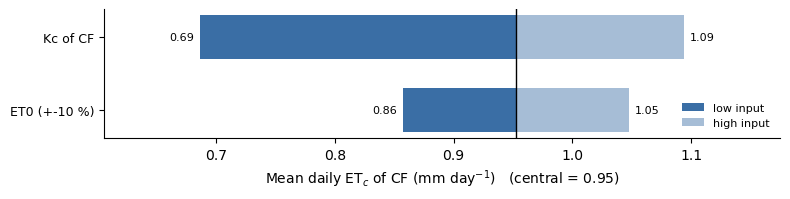

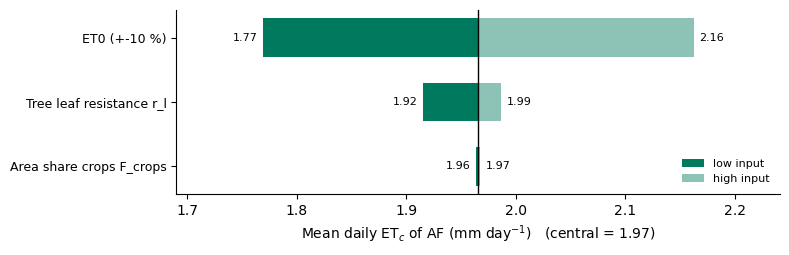

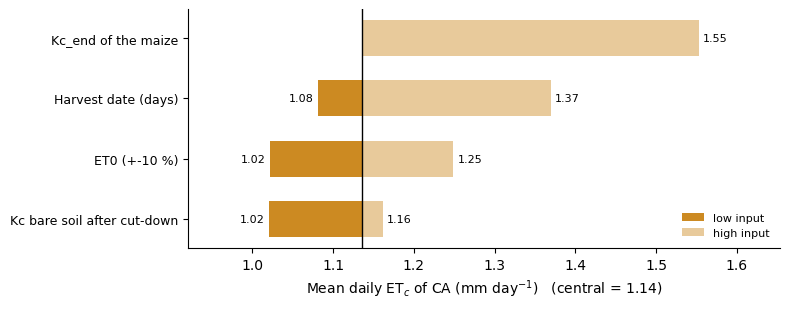

In [69]:
for plot in PLOTS:
    rows = summary.loc[plot].sort_values('range')
    base = central[plot].mean()
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(rows) + 1.0))
    for i, (label, r) in enumerate(rows.iterrows()):
        for v, alpha, lab in ((r['low input'], 1.0, 'low input'), (r['high input'], 0.45, 'high input')):
            ax.barh(i, v - base, left=base, height=0.6, color=COLORS[plot], alpha=alpha,
                    label=lab if i == 0 else None)
            right = v >= base
            if abs(v - base) > 1e-9:
                ax.text(v + (0.005 if right else -0.005), i, f'{v:.2f}', va='center',
                        ha='left' if right else 'right', fontsize=8)
    ax.axvline(base, color='black', lw=1)
    ax.set_yticks(range(len(rows)), labels=rows.index, fontsize=9)
    ax.set_xlabel(f'Mean daily ET$_c$ of {plot} (mm day$^{{-1}}$)   (central = {base:.2f})')
    lo_all, hi_all = rows[['low input', 'high input']].values.min(), rows[['low input', 'high input']].values.max()
    pad = 0.15 * (hi_all - lo_all) + 0.02
    ax.set_xlim(lo_all - pad, hi_all + pad)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='lower right', fontsize=8, frameon=False)
    plt.tight_layout()
    fig.savefig(f'ETc_tornado_{plot}.png', dpi=300, bbox_inches='tight')
    plt.show()

## 5. Daily ETc with the uncertainty range

Bars = central case; error bars = lowest and highest value of the one-at-a-time cases on that day (not all inputs wrong at the same time).
Incomplete days (e.g. the last day) are included here as the sum of the available hours: hatched bars, labelled with the number of hours. The tornado charts (section 4) still use complete days only.

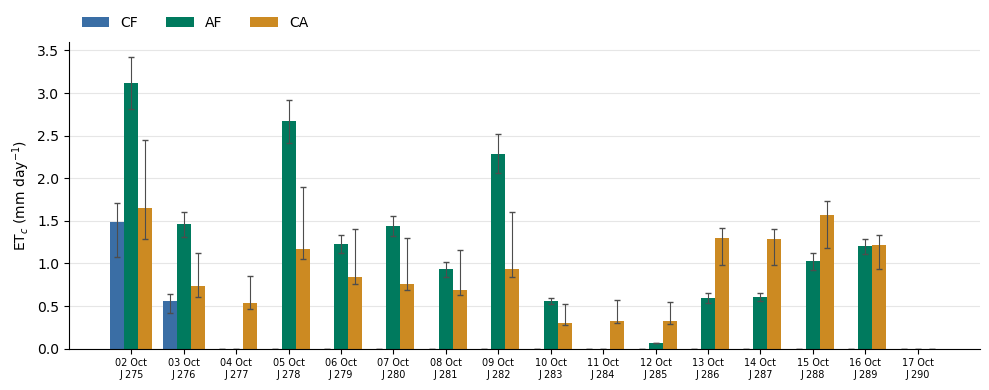

In [70]:
# Daily FINAL ETc with the uncertainty range (interception rule of each plot):
#   P + F > 0  ->  ETc = 0 ;   P + F = 0  ->  ETc = min(Kc * ET0, E0 - Ei)
# E0 and Ei come from interception_output_{plot}_WB_hourly.csv and are not changed by the cases.
# Days: from the first complete day on; the last day may be incomplete (sum of the available hours).
ic_all = []
for plot in PLOTS:
    ic = pd.read_csv(f'interception_output_{plot}_WB_hourly.csv', parse_dates=['Timestamp'])
    ic['plot'] = plot
    ic_all.append(ic[['Timestamp', 'plot', 'P_mm', 'F_mm', 'E0_mm', 'Ei_mm']])
et0_ic = et0.merge(pd.concat(ic_all), on=['Timestamp', 'plot'], how='left')
WET_F = ((et0_ic['P_mm'] + et0_ic['F_mm']) > 0).values
CAP_F = (et0_ic['E0_mm'] - et0_ic['Ei_mm']).clip(lower=0).values


def daily_etc_final(p):
    '''Daily FINAL ETc [mm/day] per plot for parameter set p (all hours with interception data).'''
    res = []
    for plot in PLOTS:
        sel = (et0_ic['plot'] == plot).values & ~np.isnan(CAP_F)
        g = et0_ic[sel]
        pot = kc_series(plot, g['J'], p).values * g['ET0'].values * p['et0_factor']
        fin = np.where(WET_F[sel], 0.0, np.minimum(pot, CAP_F[sel]))
        res.append(pd.Series(fin, index=g.index).groupby(g['J']).sum().rename(plot))
    return pd.concat(res, axis=1)


# first complete day (24 hourly values for all plots); everything before it is dropped
n_hours = et0_ic.dropna(subset=['ET0']).groupby(['J', 'plot'])['ET0'].count().unstack()
FIRST_J = n_hours[(n_hours.reindex(columns=PLOTS) >= n_full).all(axis=1)].index.min()

central_all = daily_etc_final(CENTRAL).loc[FIRST_J:]
cases_all = {}
for plot, label, key, lo, hi in FACTORS:
    targets = PLOTS if plot == 'all' else [plot]
    d_lo, d_hi = daily_etc_final({**CENTRAL, key: lo}), daily_etc_final({**CENTRAL, key: hi})
    for t in targets:
        cases_all[(t, label)] = (d_lo[t].loc[FIRST_J:], d_hi[t].loc[FIRST_J:])

lo_env = pd.concat({p: pd.concat([v[0] for (t, _), v in cases_all.items() if t == p] +
                                 [v[1] for (t, _), v in cases_all.items() if t == p], axis=1).min(axis=1)
                    for p in PLOTS}, axis=1)
hi_env = pd.concat({p: pd.concat([v[0] for (t, _), v in cases_all.items() if t == p] +
                                 [v[1] for (t, _), v in cases_all.items() if t == p], axis=1).max(axis=1)
                    for p in PLOTS}, axis=1)

n, width = len(PLOTS), 0.8 / len(PLOTS)
x = np.arange(len(central_all))
fig, ax = plt.subplots(figsize=(10, 4))
for k, plot in enumerate(PLOTS):
    c = central_all[plot]
    yerr = np.vstack([(c - lo_env[plot]).clip(lower=0), (hi_env[plot] - c).clip(lower=0)])
    ax.bar(x + (k - (n - 1) / 2) * width, c, width=width, color=COLORS[plot], label=plot,
           yerr=yerr, capsize=2, error_kw=dict(lw=0.8, ecolor='0.3'))
ax.set_xticks(x, labels=[f"{pd.Timestamp(YEAR, 1, 1) + pd.Timedelta(days=int(j) - 1):%d %b}\nJ {int(j)}"
                         for j in central_all.index], fontsize=7)
ax.set_ylabel('ET$_c$ (mm day$^{-1}$)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='0.9')
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=len(PLOTS), loc='lower left', bbox_to_anchor=(0, 1.0))
plt.tight_layout()
fig.savefig('ETc_daily_uncertainty.png', dpi=300, bbox_inches='tight')
plt.show()


### Save

In [71]:
summary.round(4).to_csv('ETc_sensitivity_summary.csv')
pd.concat({'central': central_all, 'low': lo_env, 'high': hi_env, 'n_hours': n_hours}, axis=1).round(4).to_csv('ETc_daily_with_range.csv')
print('Saved ETc_sensitivity_summary.csv and ETc_daily_with_range.csv')


Saved ETc_sensitivity_summary.csv and ETc_daily_with_range.csv


Check: max |recomputed - saved ET0| = 0.036 mm/h (should be close to 0)
CF: mean daily ET0 = 1.13, ETc_pot = 0.95, ETc = 0.14 mm/day  (15 complete days)


central  ETc low  ETc high  change low [%]  \
ETc       input                                                                 
potential Kc (0.61–0.96)              0.95     0.69      1.09          -27.86   
          Wind (2 m vs 100 m)         0.95     0.97      0.95            2.16   
          Solar radiation (±10 %)     0.95     0.87      1.03           -8.27   
final     Kc (0.61–0.96)              0.14     0.10      0.16          -27.21   
          Wind (2 m vs 100 m)         0.14     0.14      0.14            1.17   
          Solar radiation (±10 %)     0.14     0.13      0.15           -8.19   

                                   change high [%]  
ETc       input                                     
potential Kc (0.61–0.96)                     14.83  
          Wind (2 m vs 100 m)                 0.00  
          Solar radiation (±10 %)             8.33  
final     Kc (0.61–0.96)                     14.47  
          Wind (2 m vs 100 m)                 0.00  
          Solar radiation (±10 %)             8.19

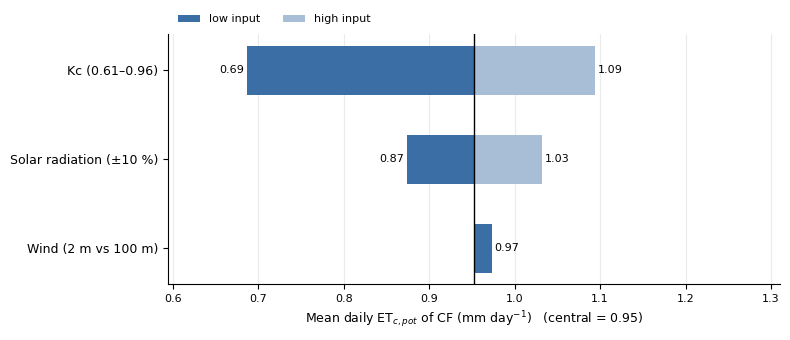

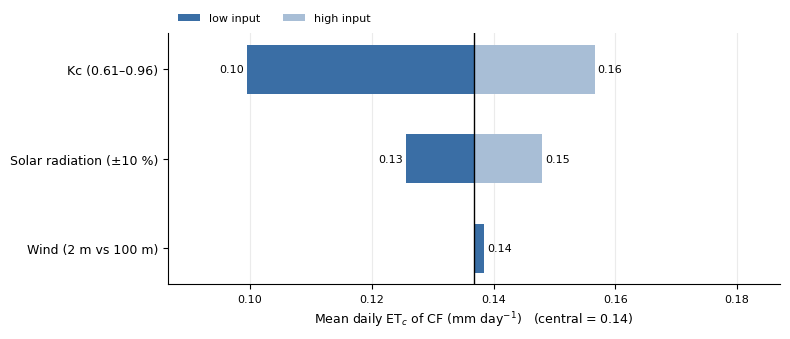

In [72]:
# Sensitivity of the POTENTIAL ETc (Kc * ET0) and of the FINAL ETc at CF to Kc, wind speed and solar radiation
# One input at a time is set low / high, everything else at its central value.
#   Kc:   central value and envelope over r_l, h and f_c (Kc notebook, section 7)
#   Wind: Open-Meteo at 100 m used directly as u2 (central) vs. reduced to 2 m with FAO-56 Eq. 47 (low)
#   Rs:   +-10 % (HOBO pyranometer in a canopy gap)
# ET0 is recomputed hourly (FAO-56 Eq. 53); only the change is added to the saved ET0:
#   ET0_case = ET0_saved + (ET0_recomputed_case - ET0_recomputed_central)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = 'ET0_results_hourly.csv'
PLOT      = 'CF'
Z         = 1650                                   # elevation of CF [m]

_kc_cf = pd.read_csv('Kc_CF.csv', index_col=0)['CF']                     # from the Kc notebook, section 7
KC, KC_RANGE = _kc_cf['Kc_now'], (_kc_cf['Kc_min_env'], _kc_cf['Kc_max_env'])   # central, envelope (r_l, h, f_c)
WIND_LOW     = 4.87 / np.log(67.8 * 100 - 5.42)    # FAO-56 Eq. 47: wind at 100 m -> 2 m (~0.55)
RS_RANGE     = (0.90, 1.10)                        # +-10 % on solar radiation
SIGMA_H      = 2.043e-10                           # Stefan-Boltzmann constant per hour [MJ m-2 h-1 K-4]

REQUIRED = ['Timestamp', 'plot', 'T_hr', 'ea', 'u2', 'Rs', 'Rso', 'ET0']
d = pd.read_csv(DATA_FILE, parse_dates=['Timestamp'])
missing = [c for c in REQUIRED if c not in d.columns]
assert not missing, f'Missing columns {missing}. Columns in the file: {list(d.columns)}'
d = d[d['plot'] == PLOT].set_index('Timestamp').sort_index()


def et0_hourly(T, ea, u2, Rs, Rso, z=Z):
    '''Hourly FAO-56 Penman-Monteith ET0 [mm/h] (Eq. 53).'''
    P     = 101.3 * ((293 - 0.0065 * z) / 293) ** 5.26                 # Eq. 7
    gamma = 0.665e-3 * P                                               # Eq. 8
    es    = 0.6108 * np.exp(17.27 * T / (T + 237.3))                   # Eq. 11
    delta = 4098 * es / (T + 237.3) ** 2                               # Eq. 13
    ratio = (Rs / Rso).where(Rso > 0.05).ffill().clip(0.3, 1.0)        # Rs/Rso; at night the last daytime value
    Rns   = 0.77 * Rs                                                  # Eq. 38
    Rnl   = SIGMA_H * (T + 273.16) ** 4 * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * ratio - 0.35)   # Eq. 39
    Rn    = Rns - Rnl                                                  # Eq. 40
    G     = np.where(Rs > 0, 0.1, 0.5) * Rn                            # Eq. 45-46
    return (0.408 * delta * (Rn - G) + gamma * 37 / (T + 273) * u2 * (es - ea)) / (delta + gamma * (1 + 0.34 * u2))


ET0_saved = d['ET0']
ET0_calc  = et0_hourly(d['T_hr'], d['ea'], d['u2'], d['Rs'], d['Rso'])
print(f'Check: max |recomputed - saved ET0| = {(ET0_calc.clip(lower=0) - ET0_saved).abs().max():.3f} mm/h '
      '(should be close to 0)')


def ET0_case(u2_factor=1.0, rs_factor=1.0):
    '''Hourly ET0 with u2 and Rs multiplied by a factor.'''
    alt = et0_hourly(d['T_hr'], d['ea'], d['u2'] * u2_factor, d['Rs'] * rs_factor, d['Rso'])
    return (ET0_saved + alt - ET0_calc).clip(lower=0)


# --- final ETc: interception model of the plot (rain + fog, Ei, E0) -------------------------
#   P + F > 0  ->  ETc = 0 ;   P + F = 0  ->  ETc = min(ETc_pot, E0 - Ei)
# E0 and Ei come from the interception model and are NOT changed by the cases below.
ic = pd.read_csv(f'interception_output_{PLOT}_WB_hourly.csv', parse_dates=['Timestamp'])
ic  = ic.set_index('Timestamp').reindex(d.index)
WET = (ic['P_mm'] + ic['F_mm']) > 0
CAP = (ic['E0_mm'] - ic['Ei_mm']).clip(lower=0)


def final(etc_pot):
    '''Final hourly ETc from a potential hourly ETc (Kc * ET0).'''
    return np.minimum(etc_pot, CAP).where(~WET, 0.0).where(CAP.notna())


# the same complete days (24 hourly values of ET0 AND interception data) for potential and final ETc
OK_DAYS = (ET0_saved.notna() & CAP.notna()).resample('D').sum() == 24


def mean_daily(et):
    '''Mean daily total [mm/day] over the complete days OK_DAYS.'''
    return et.resample('D').sum()[OK_DAYS].mean()


# Cases: (low input, high input) as HOURLY potential ETc series
ETC_CENTRAL = KC * ET0_saved
cases = {
    f'Kc ({KC_RANGE[0]:.2f}–{KC_RANGE[1]:.2f})':
        (KC_RANGE[0] * ET0_saved, KC_RANGE[1] * ET0_saved),
    'Wind (2 m vs 100 m)':
        (KC * ET0_case(u2_factor=WIND_LOW), ETC_CENTRAL),
    f'Solar radiation (±{100 * (RS_RANGE[1] - 1):.0f} %)':
        (KC * ET0_case(rs_factor=RS_RANGE[0]), KC * ET0_case(rs_factor=RS_RANGE[1])),
}

# ---- potential and final ETc for every case --------------------------------------------------
rows = []
for kind, f in [('potential', lambda e: e), ('final', final)]:
    c = mean_daily(f(ETC_CENTRAL))
    for name, (lo, hi) in cases.items():
        rows.append((kind, name, c, mean_daily(f(lo)), mean_daily(f(hi))))
sens = pd.DataFrame(rows, columns=['ETc', 'input', 'central', 'ETc low', 'ETc high']).set_index(['ETc', 'input'])
sens['change low [%]']  = 100 * (sens['ETc low']  / sens['central'] - 1)
sens['change high [%]'] = 100 * (sens['ETc high'] / sens['central'] - 1)
print(f'{PLOT}: mean daily ET0 = {mean_daily(ET0_saved):.2f}, '
      f'ETc_pot = {sens.loc["potential", "central"].iloc[0]:.2f}, '
      f'ETc = {sens.loc["final", "central"].iloc[0]:.2f} mm/day  ({OK_DAYS.sum()} complete days)')
display(sens.round(2))

# ---- tornado charts: mean daily ETc (mm/day) for potential and final ETc ----------------------
# Each chart has its own x-axis, centred on its central value with the same half-width for both,
# so the bars are not squeezed against one side and the two charts stay comparable.
order = (sens.loc['potential', 'ETc high'] - sens.loc['potential', 'ETc low']).abs().sort_values().index
C_LOW, C_HIGH = '#3A6EA5', '#A8BED6'

for kind, lab, fname in [('potential', r'ET$_{c,pot}$', f'tornado_ETc_pot_{PLOT}.png'),
                         ('final',     r'ET$_c$',         f'tornado_ETc_{PLOT}.png')]:
    s = sens.loc[kind]
    central = s['central'].iloc[0]
    dev  = (s[['ETc low', 'ETc high']].sub(s['central'], axis=0)).abs().values
    HALF = max(dev.max() * 1.35, 0.05 * central)       # half-width of THIS chart's x-axis [mm/day]
    fig, ax = plt.subplots(figsize=(8, 0.7 * len(order) + 1.4))
    for i, name in enumerate(order):
        for val_col, color, lab_leg in (('ETc low', C_LOW, 'low input'), ('ETc high', C_HIGH, 'high input')):
            v = s.loc[name, val_col]
            ax.barh(i, v - central, left=central, color=color, height=0.55, label=lab_leg if i == 0 else None)
            if abs(v - central) > 0.001:
                right = v > central
                ax.text(v + (0.01 * HALF if right else -0.01 * HALF), i, f'{v:.2f}', va='center',
                        ha='left' if right else 'right', fontsize=8)
    ax.axvline(central, color='black', lw=1)
    ax.set_yticks(range(len(order)), labels=order, fontsize=9)
    ax.set_xlim(max(0, central - HALF), central + HALF)
    ax.set_xlabel(f'Mean daily {lab} of {PLOT} (mm day$^{{-1}}$)   (central = {central:.2f})', fontsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='x', color='0.92')
    ax.set_axisbelow(True)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8, frameon=False)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()

Check: max |recomputed - saved ET0| = 0.052 mm/h (should be close to 0)
AF: mean daily ET0 = 2.28, ETc_pot = 1.97, ETc = 1.15 mm/day  (15 complete days)


central  ETc low  ETc high  \
ETc       input                                                              
potential Tree leaf resistance $r_l$               1.97     1.99      1.92   
          Crop growth stage (later vs earlier)     1.97     1.98      1.77   
          Solar radiation (±10 %)                  1.97     1.77      2.17   
final     Tree leaf resistance $r_l$               1.15     1.16      1.12   
          Crop growth stage (later vs earlier)     1.15     1.16      1.04   
          Solar radiation (±10 %)                  1.15     1.04      1.25   

                                                change low [%]  \
ETc       input                                                  
potential Tree leaf resistance $r_l$                      1.08   
          Crop growth stage (later vs earlier)            0.95   
          Solar radiation (±10 %)                       -10.15   
final     Tree leaf resistance $r_l$                      1.00   
          Crop growth stage (later vs earlier)            0.88   
          Solar radiation (±10 %)                        -9.51   

                                                change high [%]  
ETc       input                                                  
potential Tree leaf resistance $r_l$                      -2.54  
          Crop growth stage (later vs earlier)           -10.09  
          Solar radiation (±10 %)                         10.15  
final     Tree leaf resistance $r_l$                      -2.36  
          Crop growth stage (later vs earlier)            -9.37  
          Solar radiation (±10 %)                          9.27

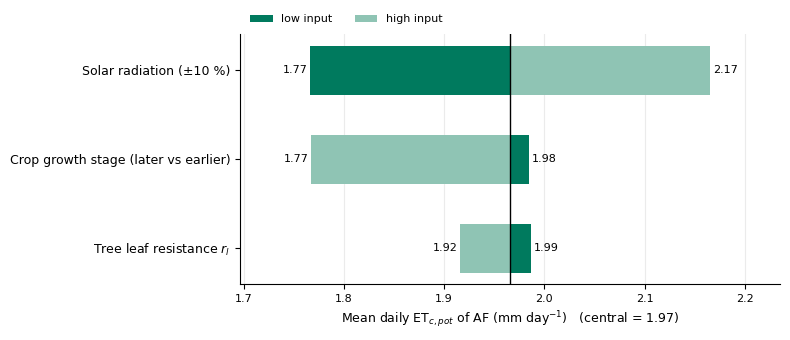

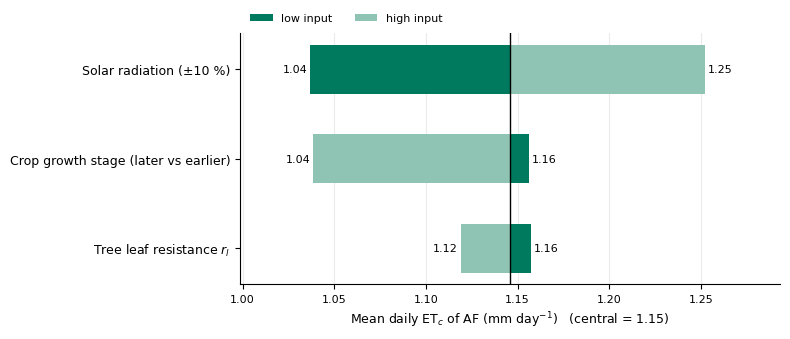

In [73]:
# Sensitivity of the POTENTIAL ETc (Kc * ET0) and of the FINAL ETc at AF to tree leaf resistance, crop growth stage and solar radiation
# One input at a time is set low / high, everything else at its central value.
#   r_l:   plot Kc with all trees at low / high r_l (Kelliher et al. 1995, g_smax +- 1 SD)
#   Stage: every crop one growth stage later (low); central = stages assigned for October
#   Rs:    +-10 % (TEMPEST / AMBIENT)
# ET0 is recomputed hourly (FAO-56 Eq. 53); only the change is added to the saved ET0:
#   ET0_case = ET0_saved + (ET0_recomputed_case - ET0_recomputed_central)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = 'ET0_results_hourly.csv'
PLOT      = 'AF'
Z         = 1420                                   # elevation of AF [m]  <- same value as in the ET0 notebook

KC    = pd.read_csv('Kc_AF.csv', index_col=0).loc['Kc_now', 'AF']                       # from the Kc notebook
_s    = pd.read_csv('Kc_AF_sensitivity.csv', index_col=0)                               # from the Kc notebook (AF sensitivity cell)
_rl   = _s.loc['Tree leaf resistance $r_l$ (all trees)']
_st   = _s.loc['Crop growth stage (earlier / later)']
KC_RL    = (_rl['Kc (low value)'], _rl['Kc (high value)'])   # plot Kc with all trees at LOW r_l, at HIGH r_l
KC_STAGE = (_st['Kc (low value)'], _st['Kc (high value)'])   # every crop one stage earlier, later                          # Kc_AF_earlier from the Kc_AF notebook
RS_RANGE      = (0.90, 1.10)                       # +-10 % on solar radiation
SIGMA_H       = 2.043e-10                          # Stefan-Boltzmann constant per hour [MJ m-2 h-1 K-4]

REQUIRED = ['Timestamp', 'plot', 'T_hr', 'ea', 'u2', 'Rs', 'Rso', 'ET0']
d = pd.read_csv(DATA_FILE, parse_dates=['Timestamp'])
missing = [c for c in REQUIRED if c not in d.columns]
assert not missing, f'Missing columns {missing}. Columns in the file: {list(d.columns)}'
d = d[d['plot'] == PLOT].set_index('Timestamp').sort_index()


def et0_hourly(T, ea, u2, Rs, Rso, z=Z):
    '''Hourly FAO-56 Penman-Monteith ET0 [mm/h] (Eq. 53).'''
    P     = 101.3 * ((293 - 0.0065 * z) / 293) ** 5.26                 # Eq. 7
    gamma = 0.665e-3 * P                                               # Eq. 8
    es    = 0.6108 * np.exp(17.27 * T / (T + 237.3))                   # Eq. 11
    delta = 4098 * es / (T + 237.3) ** 2                               # Eq. 13
    ratio = (Rs / Rso).where(Rso > 0.05).ffill().clip(0.3, 1.0)        # Rs/Rso; at night the last daytime value
    Rns   = 0.77 * Rs                                                  # Eq. 38
    Rnl   = SIGMA_H * (T + 273.16) ** 4 * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * ratio - 0.35)   # Eq. 39
    Rn    = Rns - Rnl                                                  # Eq. 40
    G     = np.where(Rs > 0, 0.1, 0.5) * Rn                            # Eq. 45-46
    return (0.408 * delta * (Rn - G) + gamma * 37 / (T + 273) * u2 * (es - ea)) / (delta + gamma * (1 + 0.34 * u2))


ET0_saved = d['ET0']
ET0_calc  = et0_hourly(d['T_hr'], d['ea'], d['u2'], d['Rs'], d['Rso'])
print(f'Check: max |recomputed - saved ET0| = {(ET0_calc.clip(lower=0) - ET0_saved).abs().max():.3f} mm/h '
      '(should be close to 0)')


def ET0_case(u2_factor=1.0, rs_factor=1.0):
    '''Hourly ET0 with u2 and Rs multiplied by a factor.'''
    alt = et0_hourly(d['T_hr'], d['ea'], d['u2'] * u2_factor, d['Rs'] * rs_factor, d['Rso'])
    return (ET0_saved + alt - ET0_calc).clip(lower=0)


# --- final ETc: interception model of the plot (rain + fog, Ei, E0) -------------------------
#   P + F > 0  ->  ETc = 0 ;   P + F = 0  ->  ETc = min(ETc_pot, E0 - Ei)
# E0 and Ei come from the interception model and are NOT changed by the cases below.
ic = pd.read_csv(f'interception_output_{PLOT}_WB_hourly.csv', parse_dates=['Timestamp'])
ic  = ic.set_index('Timestamp').reindex(d.index)
WET = (ic['P_mm'] + ic['F_mm']) > 0
CAP = (ic['E0_mm'] - ic['Ei_mm']).clip(lower=0)


def final(etc_pot):
    '''Final hourly ETc from a potential hourly ETc (Kc * ET0).'''
    return np.minimum(etc_pot, CAP).where(~WET, 0.0).where(CAP.notna())


# the same complete days (24 hourly values of ET0 AND interception data) for potential and final ETc
OK_DAYS = (ET0_saved.notna() & CAP.notna()).resample('D').sum() == 24


def mean_daily(et):
    '''Mean daily total [mm/day] over the complete days OK_DAYS.'''
    return et.resample('D').sum()[OK_DAYS].mean()


# Cases: (low input, high input) as HOURLY potential ETc series
ETC_CENTRAL = KC * ET0_saved
cases = {
    'Tree leaf resistance $r_l$':
        (KC_RL[0] * ET0_saved, KC_RL[1] * ET0_saved),
    'Crop growth stage (later vs earlier)':
        (KC_STAGE[0] * ET0_saved, KC_STAGE[1] * ET0_saved),
    f'Solar radiation (±{100 * (RS_RANGE[1] - 1):.0f} %)':
        (KC * ET0_case(rs_factor=RS_RANGE[0]), KC * ET0_case(rs_factor=RS_RANGE[1])),
}

# ---- potential and final ETc for every case --------------------------------------------------
rows = []
for kind, f in [('potential', lambda e: e), ('final', final)]:
    c = mean_daily(f(ETC_CENTRAL))
    for name, (lo, hi) in cases.items():
        rows.append((kind, name, c, mean_daily(f(lo)), mean_daily(f(hi))))
sens = pd.DataFrame(rows, columns=['ETc', 'input', 'central', 'ETc low', 'ETc high']).set_index(['ETc', 'input'])
sens['change low [%]']  = 100 * (sens['ETc low']  / sens['central'] - 1)
sens['change high [%]'] = 100 * (sens['ETc high'] / sens['central'] - 1)
print(f'{PLOT}: mean daily ET0 = {mean_daily(ET0_saved):.2f}, '
      f'ETc_pot = {sens.loc["potential", "central"].iloc[0]:.2f}, '
      f'ETc = {sens.loc["final", "central"].iloc[0]:.2f} mm/day  ({OK_DAYS.sum()} complete days)')
display(sens.round(2))

# ---- tornado charts: mean daily ETc (mm/day) for potential and final ETc ----------------------
# Each chart has its own x-axis, centred on its central value with the same half-width for both,
# so the bars are not squeezed against one side and the two charts stay comparable.
order = (sens.loc['potential', 'ETc high'] - sens.loc['potential', 'ETc low']).abs().sort_values().index
C_LOW, C_HIGH = '#007A5E', '#8FC4B4'

for kind, lab, fname in [('potential', r'ET$_{c,pot}$', f'tornado_ETc_pot_{PLOT}.png'),
                         ('final',     r'ET$_c$',         f'tornado_ETc_{PLOT}.png')]:
    s = sens.loc[kind]
    central = s['central'].iloc[0]
    dev  = (s[['ETc low', 'ETc high']].sub(s['central'], axis=0)).abs().values
    HALF = max(dev.max() * 1.35, 0.05 * central)       # half-width of THIS chart's x-axis [mm/day]
    fig, ax = plt.subplots(figsize=(8, 0.7 * len(order) + 1.4))
    for i, name in enumerate(order):
        for val_col, color, lab_leg in (('ETc low', C_LOW, 'low input'), ('ETc high', C_HIGH, 'high input')):
            v = s.loc[name, val_col]
            ax.barh(i, v - central, left=central, color=color, height=0.55, label=lab_leg if i == 0 else None)
            if abs(v - central) > 0.001:
                right = v > central
                ax.text(v + (0.01 * HALF if right else -0.01 * HALF), i, f'{v:.2f}', va='center',
                        ha='left' if right else 'right', fontsize=8)
    ax.axvline(central, color='black', lw=1)
    ax.set_yticks(range(len(order)), labels=order, fontsize=9)
    ax.set_xlim(max(0, central - HALF), central + HALF)
    ax.set_xlabel(f'Mean daily {lab} of {PLOT} (mm day$^{{-1}}$)   (central = {central:.2f})', fontsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='x', color='0.92')
    ax.set_axisbelow(True)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8, frameon=False)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()

Check: max |recomputed - saved ET0| = 0.047 mm/h (should be close to 0)
CA: mean daily ET0 = 2.27, ETc_pot = 1.14, ETc = 0.91 mm/day  (15 complete days)


central  ETc low  ETc high  \
ETc       input                                                         
potential Kc_end of the maize (0.35–0.60)     1.14     1.14      1.55   
          Harvest date (±10 days)             1.14     1.08      1.37   
          Wind (reduced to 2 m)               1.14     1.16      1.14   
          Solar radiation (±10 %)             1.14     1.03      1.24   
final     Kc_end of the maize (0.35–0.60)     0.91     0.91      1.25   
          Harvest date (±10 days)             0.91     0.86      1.11   
          Wind (reduced to 2 m)               0.91     0.93      0.91   
          Solar radiation (±10 %)             0.91     0.83      0.99   

                                           change low [%]  change high [%]  
ETc       input                                                             
potential Kc_end of the maize (0.35–0.60)            0.00            36.83  
          Harvest date (±10 days)                   -4.79            20.61  
          Wind (reduced to 2 m)                      2.24             0.00  
          Solar radiation (±10 %)                   -9.03             9.03  
final     Kc_end of the maize (0.35–0.60)            0.00            37.54  
          Harvest date (±10 days)                   -5.36            21.35  
          Wind (reduced to 2 m)                      1.93             0.00  
          Solar radiation (±10 %)                   -8.94             8.87

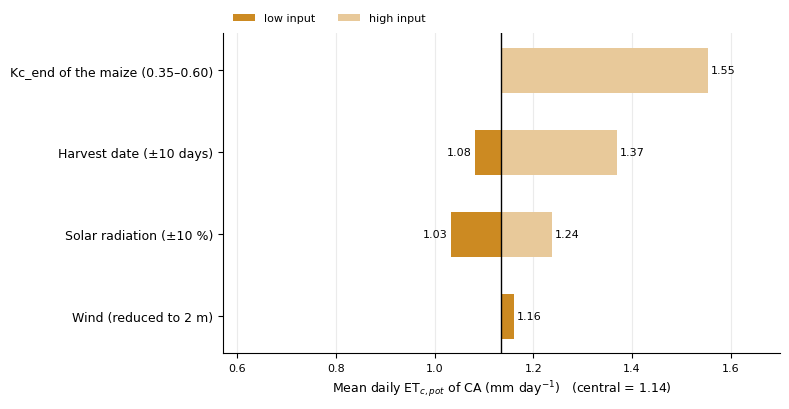

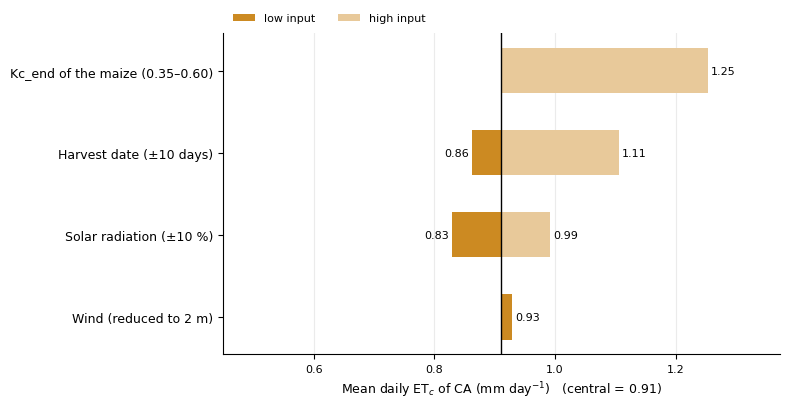

In [74]:
# Sensitivity of the POTENTIAL ETc (Kc * ET0) and of the FINAL ETc at CA to Kc_end, harvest date, wind speed and solar radiation
# One input at a time is set low / high, everything else at its central value.
#   Kc_end:  0.35-0.60 (FAO-56 Table 12: dried in field / harvested moist), central 0.35
#   Harvest: end of the late stage shifted by -10 / +10 days
#   Wind:    Open-Meteo at 100 m used directly as u2 (central) vs. reduced to 2 m with FAO-56 Eq. 47 (low)
#   Rs:      +-10 % (TEMPEST / AMBIENT)
# The bare-soil Kc after the cut-down is not varied: the cut-down (13 Oct) falls after the last complete day.
# ET0 is recomputed hourly (FAO-56 Eq. 53); only the change is added to the saved ET0:
#   ET0_case = ET0_saved + (ET0_recomputed_case - ET0_recomputed_central)

from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = 'ET0_results_hourly.csv'
PLOT      = 'CA'
Z         = 1690                                   # elevation of CA [m]  <- same value as in the ET0 notebook
YEAR      = 2026

# maize curve (same as kc_curve_CA)
SOWING, CUT_DOWN = date(YEAR, 4, 10), date(YEAR, 10, 13)
L_INI, L_DEV, L_MID, L_LATE = 30, 50, 60, 40       # FAO-56 Table 11 [days]
KC_INI, KC_MID = 0.85, 1.13
KC_AFTER_CUT   = 0.90                              # bare soil after the cut-down (Fig. 29)

KC_END,  KC_END_RANGE  = 0.35, (0.35, 0.60)        # FAO-56 Table 12: dried in field / harvested moist
HARVEST_SHIFT_RANGE    = (-10, 10)                 # [days] shift of the end of the late stage
WIND_LOW     = 4.87 / np.log(67.8 * 100 - 5.42)    # FAO-56 Eq. 47: wind at 100 m -> 2 m (~0.55)
RS_RANGE     = (0.90, 1.10)                        # +-10 % on solar radiation
SIGMA_H      = 2.043e-10                           # Stefan-Boltzmann constant per hour [MJ m-2 h-1 K-4]

REQUIRED = ['Timestamp', 'plot', 'J', 'T_hr', 'ea', 'u2', 'Rs', 'Rso', 'ET0']
d = pd.read_csv(DATA_FILE, parse_dates=['Timestamp'])
missing = [c for c in REQUIRED if c not in d.columns]
assert not missing, f'Missing columns {missing}. Columns in the file: {list(d.columns)}'
d = d[d['plot'] == PLOT].set_index('Timestamp').sort_index()


def kc_maize_CA(J, kc_end=KC_END, harvest_shift=0):
    '''Kc of CA on day of year J (FAO-56 Eq. 66 curve; after the harvest the dry plants keep Kc_end until the cut-down).'''
    day = date(YEAR, 1, 1) + timedelta(days=int(J) - 1)
    if day >= CUT_DOWN:
        return KC_AFTER_CUT
    i, l_late = (day - SOWING).days, L_LATE + harvest_shift
    if i < 0:
        return np.nan
    if i < L_INI:
        return KC_INI
    if i < L_INI + L_DEV:
        return KC_INI + (i - L_INI) / L_DEV * (KC_MID - KC_INI)
    if i < L_INI + L_DEV + L_MID:
        return KC_MID
    if i < L_INI + L_DEV + L_MID + l_late:
        return KC_MID + (i - (L_INI + L_DEV + L_MID)) / l_late * (kc_end - KC_MID)
    return kc_end


def Kc_hourly(**kw):
    '''Hourly Kc series of CA for the given maize parameters.'''
    days = d['J'].unique()
    return d['J'].map({j: kc_maize_CA(j, **kw) for j in days})


def et0_hourly(T, ea, u2, Rs, Rso, z=Z):
    '''Hourly FAO-56 Penman-Monteith ET0 [mm/h] (Eq. 53).'''
    P     = 101.3 * ((293 - 0.0065 * z) / 293) ** 5.26                 # Eq. 7
    gamma = 0.665e-3 * P                                               # Eq. 8
    es    = 0.6108 * np.exp(17.27 * T / (T + 237.3))                   # Eq. 11
    delta = 4098 * es / (T + 237.3) ** 2                               # Eq. 13
    ratio = (Rs / Rso).where(Rso > 0.05).ffill().clip(0.3, 1.0)        # Rs/Rso; at night the last daytime value
    Rns   = 0.77 * Rs                                                  # Eq. 38
    Rnl   = SIGMA_H * (T + 273.16) ** 4 * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * ratio - 0.35)   # Eq. 39
    Rn    = Rns - Rnl                                                  # Eq. 40
    G     = np.where(Rs > 0, 0.1, 0.5) * Rn                            # Eq. 45-46
    return (0.408 * delta * (Rn - G) + gamma * 37 / (T + 273) * u2 * (es - ea)) / (delta + gamma * (1 + 0.34 * u2))


ET0_saved = d['ET0']
ET0_calc  = et0_hourly(d['T_hr'], d['ea'], d['u2'], d['Rs'], d['Rso'])
print(f'Check: max |recomputed - saved ET0| = {(ET0_calc.clip(lower=0) - ET0_saved).abs().max():.3f} mm/h '
      '(should be close to 0)')


def ET0_case(u2_factor=1.0, rs_factor=1.0):
    '''Hourly ET0 with u2 and Rs multiplied by a factor.'''
    alt = et0_hourly(d['T_hr'], d['ea'], d['u2'] * u2_factor, d['Rs'] * rs_factor, d['Rso'])
    return (ET0_saved + alt - ET0_calc).clip(lower=0)


# --- final ETc: interception model of the plot (rain + fog, Ei, E0) -------------------------
#   P + F > 0  ->  ETc = 0 ;   P + F = 0  ->  ETc = min(ETc_pot, E0 - Ei)
# E0 and Ei come from the interception model and are NOT changed by the cases below.
ic = pd.read_csv(f'interception_output_{PLOT}_WB_hourly.csv', parse_dates=['Timestamp'])
ic  = ic.set_index('Timestamp').reindex(d.index)
WET = (ic['P_mm'] + ic['F_mm']) > 0
CAP = (ic['E0_mm'] - ic['Ei_mm']).clip(lower=0)


def final(etc_pot):
    '''Final hourly ETc from a potential hourly ETc (Kc * ET0).'''
    return np.minimum(etc_pot, CAP).where(~WET, 0.0).where(CAP.notna())


# the same complete days (24 hourly values of ET0 AND interception data) for potential and final ETc
OK_DAYS = (ET0_saved.notna() & CAP.notna()).resample('D').sum() == 24


def mean_daily(et):
    '''Mean daily total [mm/day] over the complete days OK_DAYS.'''
    return et.resample('D').sum()[OK_DAYS].mean()


# Cases: (low input, high input) as HOURLY potential ETc series
KC = Kc_hourly()                                   # central hourly Kc
ETC_CENTRAL = KC * ET0_saved
cases = {
    f'Kc_end of the maize ({KC_END_RANGE[0]:.2f}–{KC_END_RANGE[1]:.2f})':
        (Kc_hourly(kc_end=KC_END_RANGE[0]) * ET0_saved, Kc_hourly(kc_end=KC_END_RANGE[1]) * ET0_saved),
    f'Harvest date (±{HARVEST_SHIFT_RANGE[1]} days)':
        (Kc_hourly(harvest_shift=HARVEST_SHIFT_RANGE[0]) * ET0_saved,
         Kc_hourly(harvest_shift=HARVEST_SHIFT_RANGE[1]) * ET0_saved),
    'Wind (reduced to 2 m)':
        (KC * ET0_case(u2_factor=WIND_LOW), ETC_CENTRAL),
    f'Solar radiation (±{100 * (RS_RANGE[1] - 1):.0f} %)':
        (KC * ET0_case(rs_factor=RS_RANGE[0]), KC * ET0_case(rs_factor=RS_RANGE[1])),
}

# ---- potential and final ETc for every case --------------------------------------------------
rows = []
for kind, f in [('potential', lambda e: e), ('final', final)]:
    c = mean_daily(f(ETC_CENTRAL))
    for name, (lo, hi) in cases.items():
        rows.append((kind, name, c, mean_daily(f(lo)), mean_daily(f(hi))))
sens = pd.DataFrame(rows, columns=['ETc', 'input', 'central', 'ETc low', 'ETc high']).set_index(['ETc', 'input'])
sens['change low [%]']  = 100 * (sens['ETc low']  / sens['central'] - 1)
sens['change high [%]'] = 100 * (sens['ETc high'] / sens['central'] - 1)
print(f'{PLOT}: mean daily ET0 = {mean_daily(ET0_saved):.2f}, '
      f'ETc_pot = {sens.loc["potential", "central"].iloc[0]:.2f}, '
      f'ETc = {sens.loc["final", "central"].iloc[0]:.2f} mm/day  ({OK_DAYS.sum()} complete days)')
display(sens.round(2))

# ---- tornado charts: mean daily ETc (mm/day) for potential and final ETc ----------------------
# Each chart has its own x-axis, centred on its central value with the same half-width for both,
# so the bars are not squeezed against one side and the two charts stay comparable.
order = (sens.loc['potential', 'ETc high'] - sens.loc['potential', 'ETc low']).abs().sort_values().index
C_LOW, C_HIGH = '#CC8A22', '#E8C99A'

for kind, lab, fname in [('potential', r'ET$_{c,pot}$', f'tornado_ETc_pot_{PLOT}.png'),
                         ('final',     r'ET$_c$',         f'tornado_ETc_{PLOT}.png')]:
    s = sens.loc[kind]
    central = s['central'].iloc[0]
    dev  = (s[['ETc low', 'ETc high']].sub(s['central'], axis=0)).abs().values
    HALF = max(dev.max() * 1.35, 0.05 * central)       # half-width of THIS chart's x-axis [mm/day]
    fig, ax = plt.subplots(figsize=(8, 0.7 * len(order) + 1.4))
    for i, name in enumerate(order):
        for val_col, color, lab_leg in (('ETc low', C_LOW, 'low input'), ('ETc high', C_HIGH, 'high input')):
            v = s.loc[name, val_col]
            ax.barh(i, v - central, left=central, color=color, height=0.55, label=lab_leg if i == 0 else None)
            if abs(v - central) > 0.001:
                right = v > central
                ax.text(v + (0.01 * HALF if right else -0.01 * HALF), i, f'{v:.2f}', va='center',
                        ha='left' if right else 'right', fontsize=8)
    ax.axvline(central, color='black', lw=1)
    ax.set_yticks(range(len(order)), labels=order, fontsize=9)
    ax.set_xlim(max(0, central - HALF), central + HALF)
    ax.set_xlabel(f'Mean daily {lab} of {PLOT} (mm day$^{{-1}}$)   (central = {central:.2f})', fontsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='x', color='0.92')
    ax.set_axisbelow(True)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8, frameon=False)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()